In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import glob
import os
import cmath 
import json
import seaborn as sns
from collections import Counter
from scipy.stats import linregress
import PyQt5
%matplotlib qt
import mne

MNE is an open source python package made for exploring, visualizing, and analyzing human neurophysiological data: MEG, EEG, sEEG, ECoG, NIRS, and more. [link to mne documentation](https://mne.tools/stable/index.html)

Ignorer MaxFilter signifie pas de SSS, pas de tSSS, pas de compensation du champ externe, pas de correction du mouvement. 

Donc OK pour analyses simples (PSD, time-frequency, ICA exploratoire) mais pas idéal pour source reconstruction ou analyses fines de topographie

## **Data Loading and informations**

### loading

In [50]:
raw = mne.io.read_raw_fif("/Users/elodiehusson/Desktop/Projet/Tâche MEG/run01.fif", preload=True, allow_maxshield=True)

Opening raw data file /Users/elodiehusson/Desktop/Projet/Tâche MEG/run01.fif...
    Read a total of 13 projection items:
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
        generated with dossp-2.1 (1 x 306)  idle
    Range : 529000 ... 912999 =    529.000 ...   912.999 secs
Ready.
Reading 0 ... 383999  =      0.000 ...   383.999 secs...


/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_63514/1066726590.py:1: RuntimeWarning: This filename (/Users/elodiehusson/Desktop/Projet/Tâche MEG/run01.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif("/Users/elodiehusson/Desktop/Projet/Tâche MEG/run01.fif", preload=True, allow_maxshield=True)
/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_63514/1066726590.py:1: RuntimeWarning: This file contains raw Internal Active Shielding data. It may be distorted. Elekta recommends it be run through MaxFilter to produce reliable results. Consider closing the file and running MaxFilter on the data.
  raw = mne.io.read_raw_fif("/Users/elodiehusson/Desktop/Projet/Tâche MEG/run01.fif", preload=True, allow_maxshield=True)


From the raw object, we can see that there are 306 data channels : 102 are magnetometers, and 204 are gradiometers. This is a normal protocol for MEG, we have 1 magn and 2 gradio for each position. So we have triplets. Sampling rate is at 1000 Hz, which is a normal rate : it give a good temporal resolution for the ERF / time-frequency. 

### informations

In [3]:
raw.info

<Info | 26 non-empty values
 acq_pars: ACQactiveGround 0 ACQch.BIO001.gain 2000 ACQch.BIO001.highpass ...
 bads: []
 ch_names: BIO001, BIO002, BIO003, EXCI, IASX+, IASX-, IASY+, IASY-, IASZ+, ...
 chs: 3 BIO, 1 Flux excitation channel, 11 Internal Active Shielding data (Triux systems), 102 Magnetometers, 204 Gradiometers, 5 misc, 1 Stimulus, 1 System status channel information (Triux systems)
 custom_ref_applied: False
 description: TRIUX system at LaPitie
 dev_head_t: MEG device -> head transform
 dig: 231 items (3 Cardinal, 4 HPI, 224 Extra)
 events: 1 item (list)
 experimenter: Common User (acq)
 file_id: 4 items (dict)
 gantry_angle: 68.0
 highpass: 0.0 Hz
 hpi_meas: 1 item (list)
 hpi_results: 1 item (list)
 hpi_subsystem: 3 items (dict)
 line_freq: 50.0
 lowpass: 330.0 Hz
 maxshield: True
 meas_date: 2026-02-25 13:43:04 UTC
 meas_id: 4 items (dict)
 nchan: 328
 proc_history: 1 item (list)
 proj_id: 110
 proj_name: frint
 projs: generated with dossp-2.1: off, generated with dossp-2.1: off, ...
 sfreq: 1000.0 Hz
 subject_info: <subject_info | id: 1777, last_name: frint_pilote, first_name: p, birthday: 1980-01-01, sex: 1, hand: 1>
>

### channels informations

In [4]:
mne.channel_indices_by_type(raw.info)

{'eeg': [],
 'csd': [],
 'stim': [326],
 'eog': [],
 'ecg': [],
 'emg': [],
 'misc': [321, 322, 323, 324, 325],
 'resp': [],
 'chpi': [],
 'exci': [3],
 'ias': [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
 'syst': [327],
 'seeg': [],
 'dipole': [],
 'gof': [],
 'bio': [0, 1, 2],
 'ecog': [],
 'dbs': [],
 'temperature': [],
 'gsr': [],
 'ref_meg': [],
 'mag': [15,
  18,
  21,
  24,
  27,
  30,
  33,
  36,
  39,
  42,
  45,
  48,
  51,
  54,
  57,
  60,
  63,
  66,
  69,
  72,
  75,
  78,
  81,
  84,
  87,
  90,
  93,
  96,
  99,
  102,
  105,
  108,
  111,
  114,
  117,
  120,
  123,
  126,
  129,
  132,
  135,
  138,
  141,
  144,
  147,
  150,
  153,
  156,
  159,
  162,
  165,
  168,
  171,
  174,
  177,
  180,
  183,
  186,
  189,
  192,
  195,
  198,
  201,
  204,
  207,
  210,
  213,
  216,
  219,
  222,
  225,
  228,
  231,
  234,
  237,
  240,
  243,
  246,
  249,
  252,
  255,
  258,
  261,
  264,
  267,
  270,
  273,
  276,
  279,
  282,
  285,
  288,
  291,
  294,
  297,
  300,
  

## **Data plotting**

Using matplotlib as 2D backend.


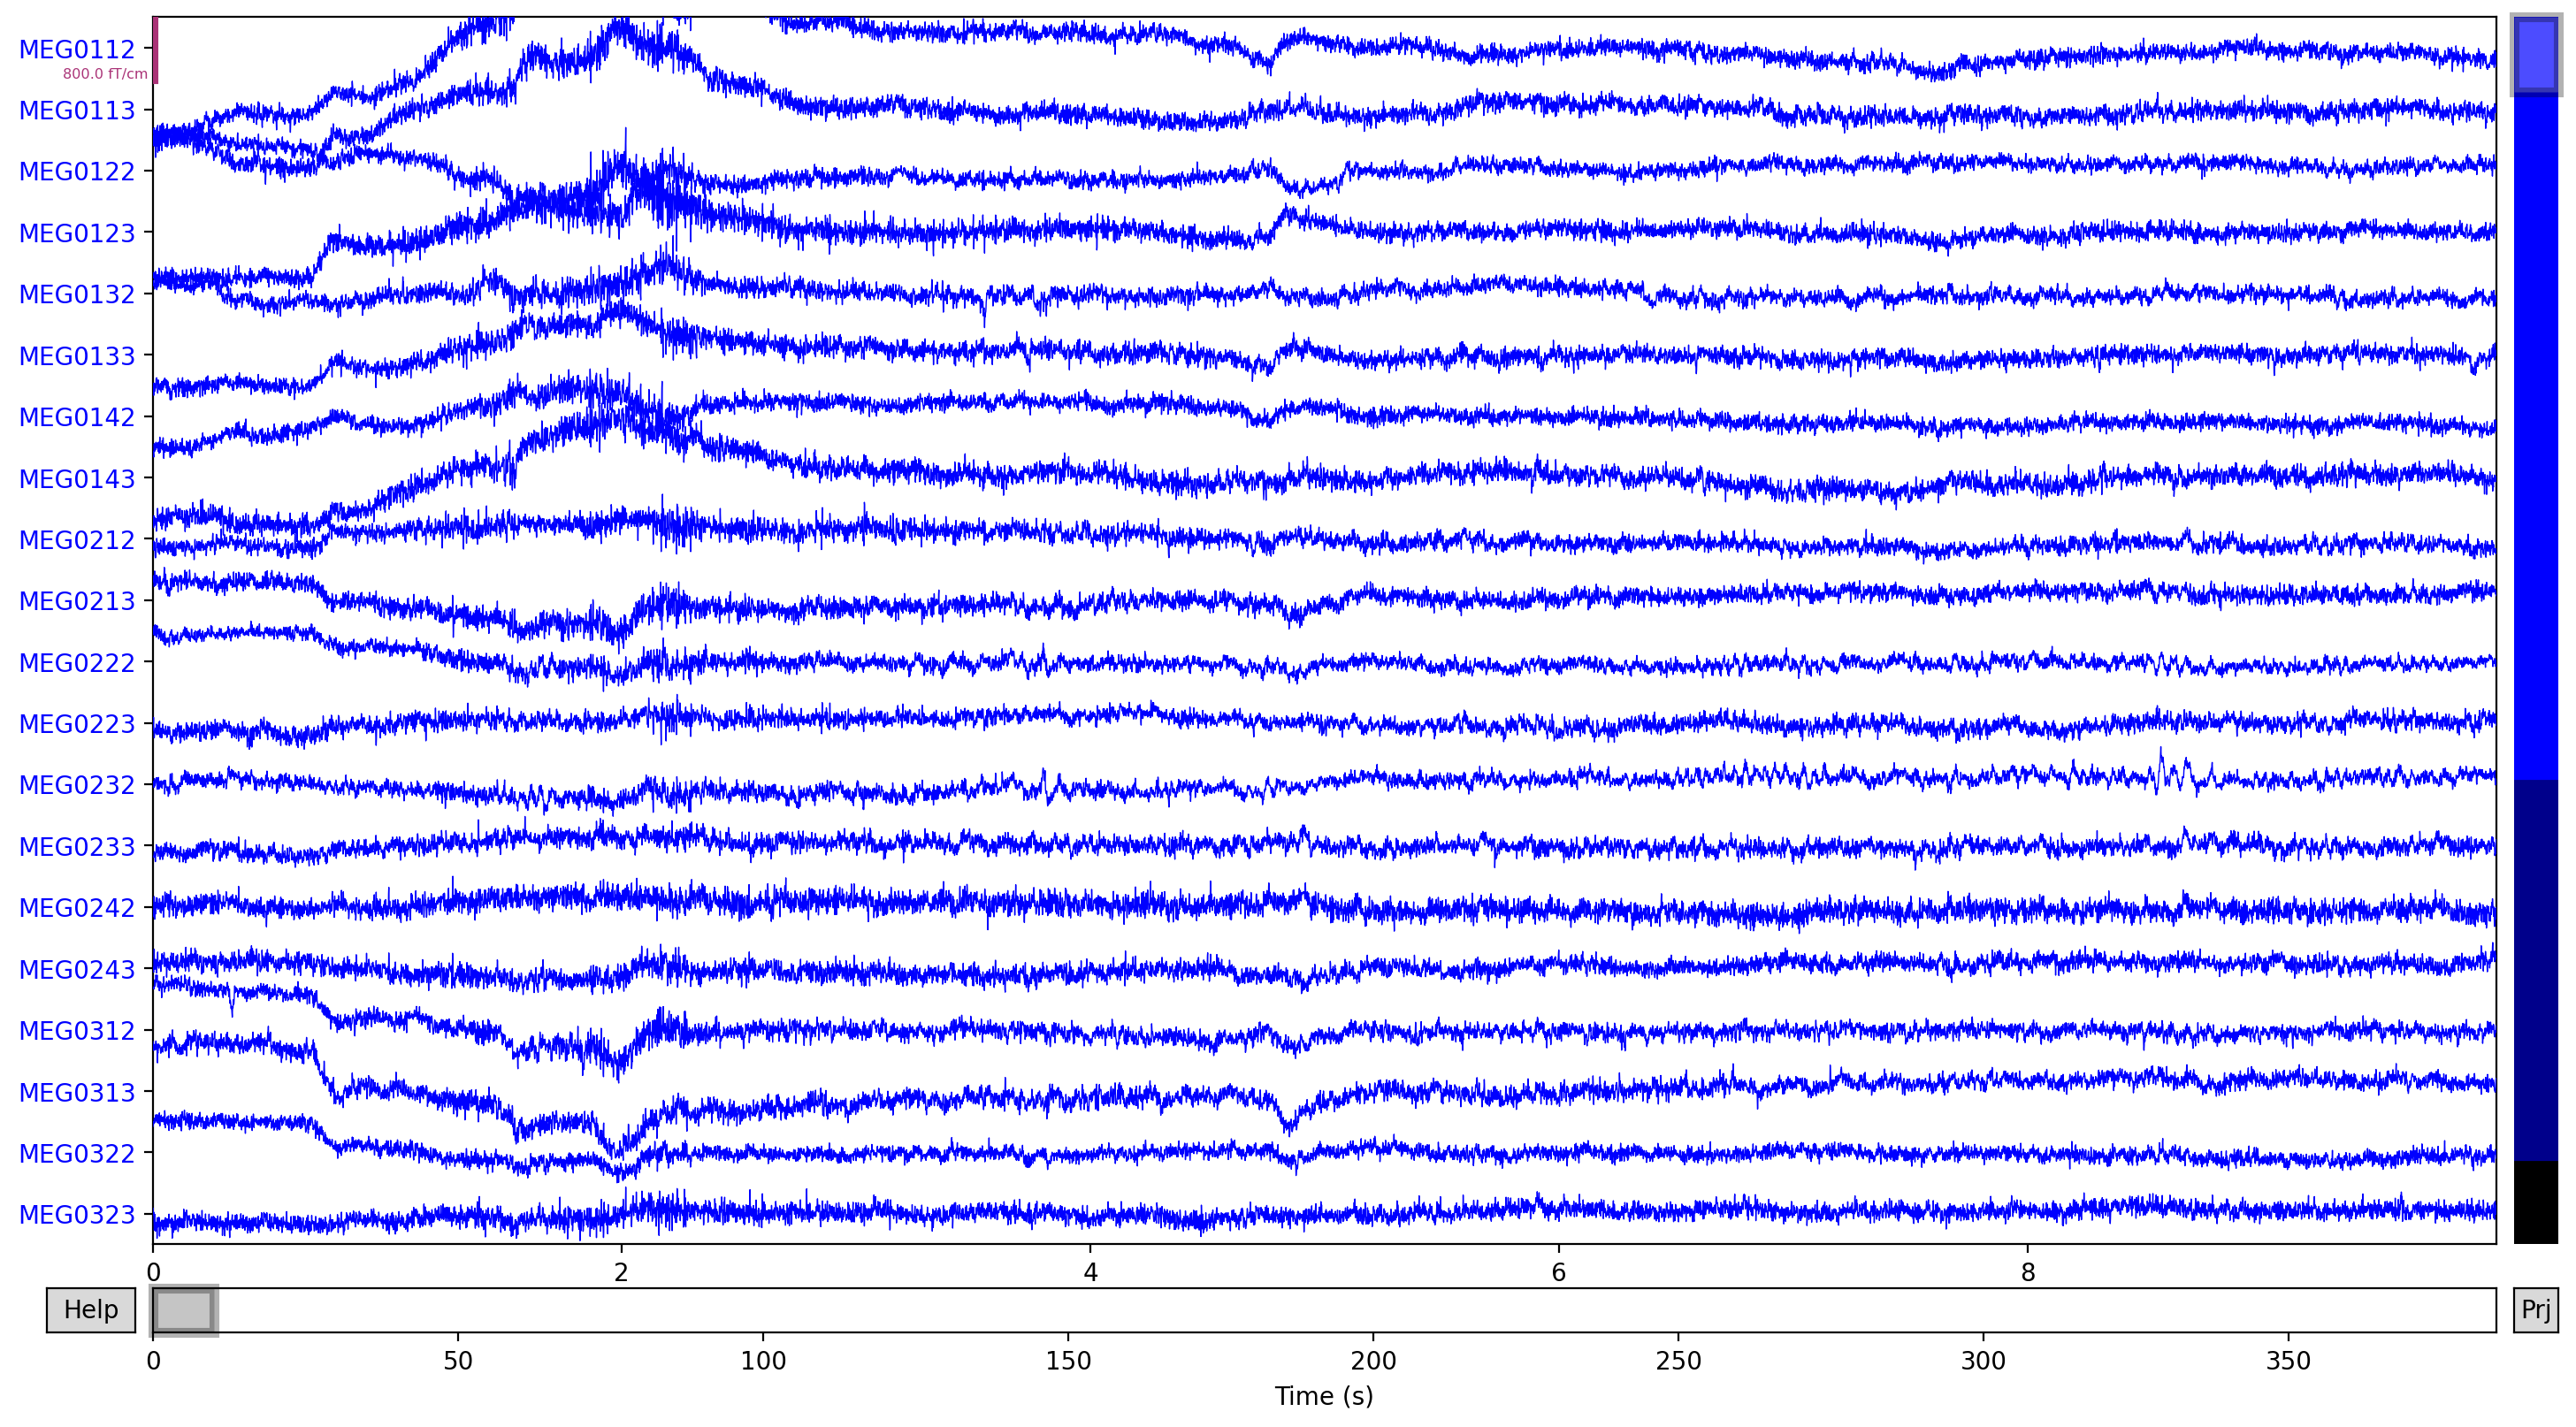

In [5]:
raw.plot()

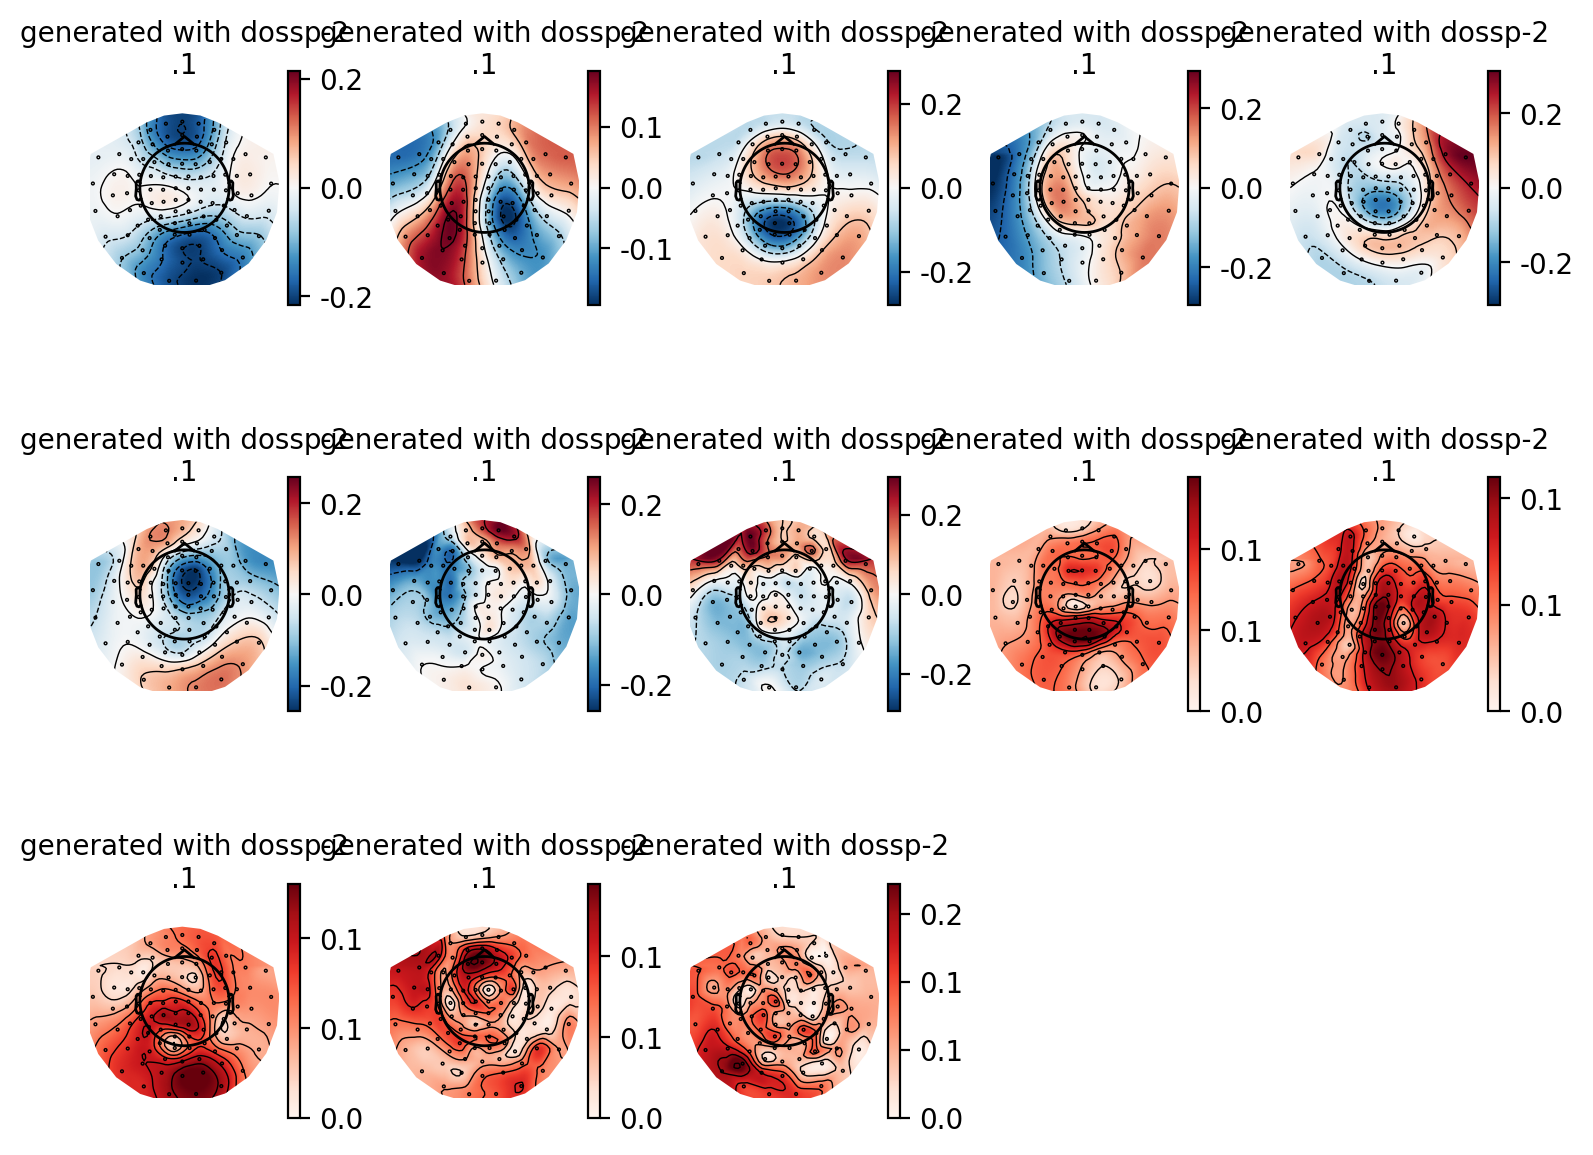

In [6]:
raw.plot_projs_topomap(colorbar=True)

Effective window size : 2.048 (s)
Plotting power spectral density (dB=True).


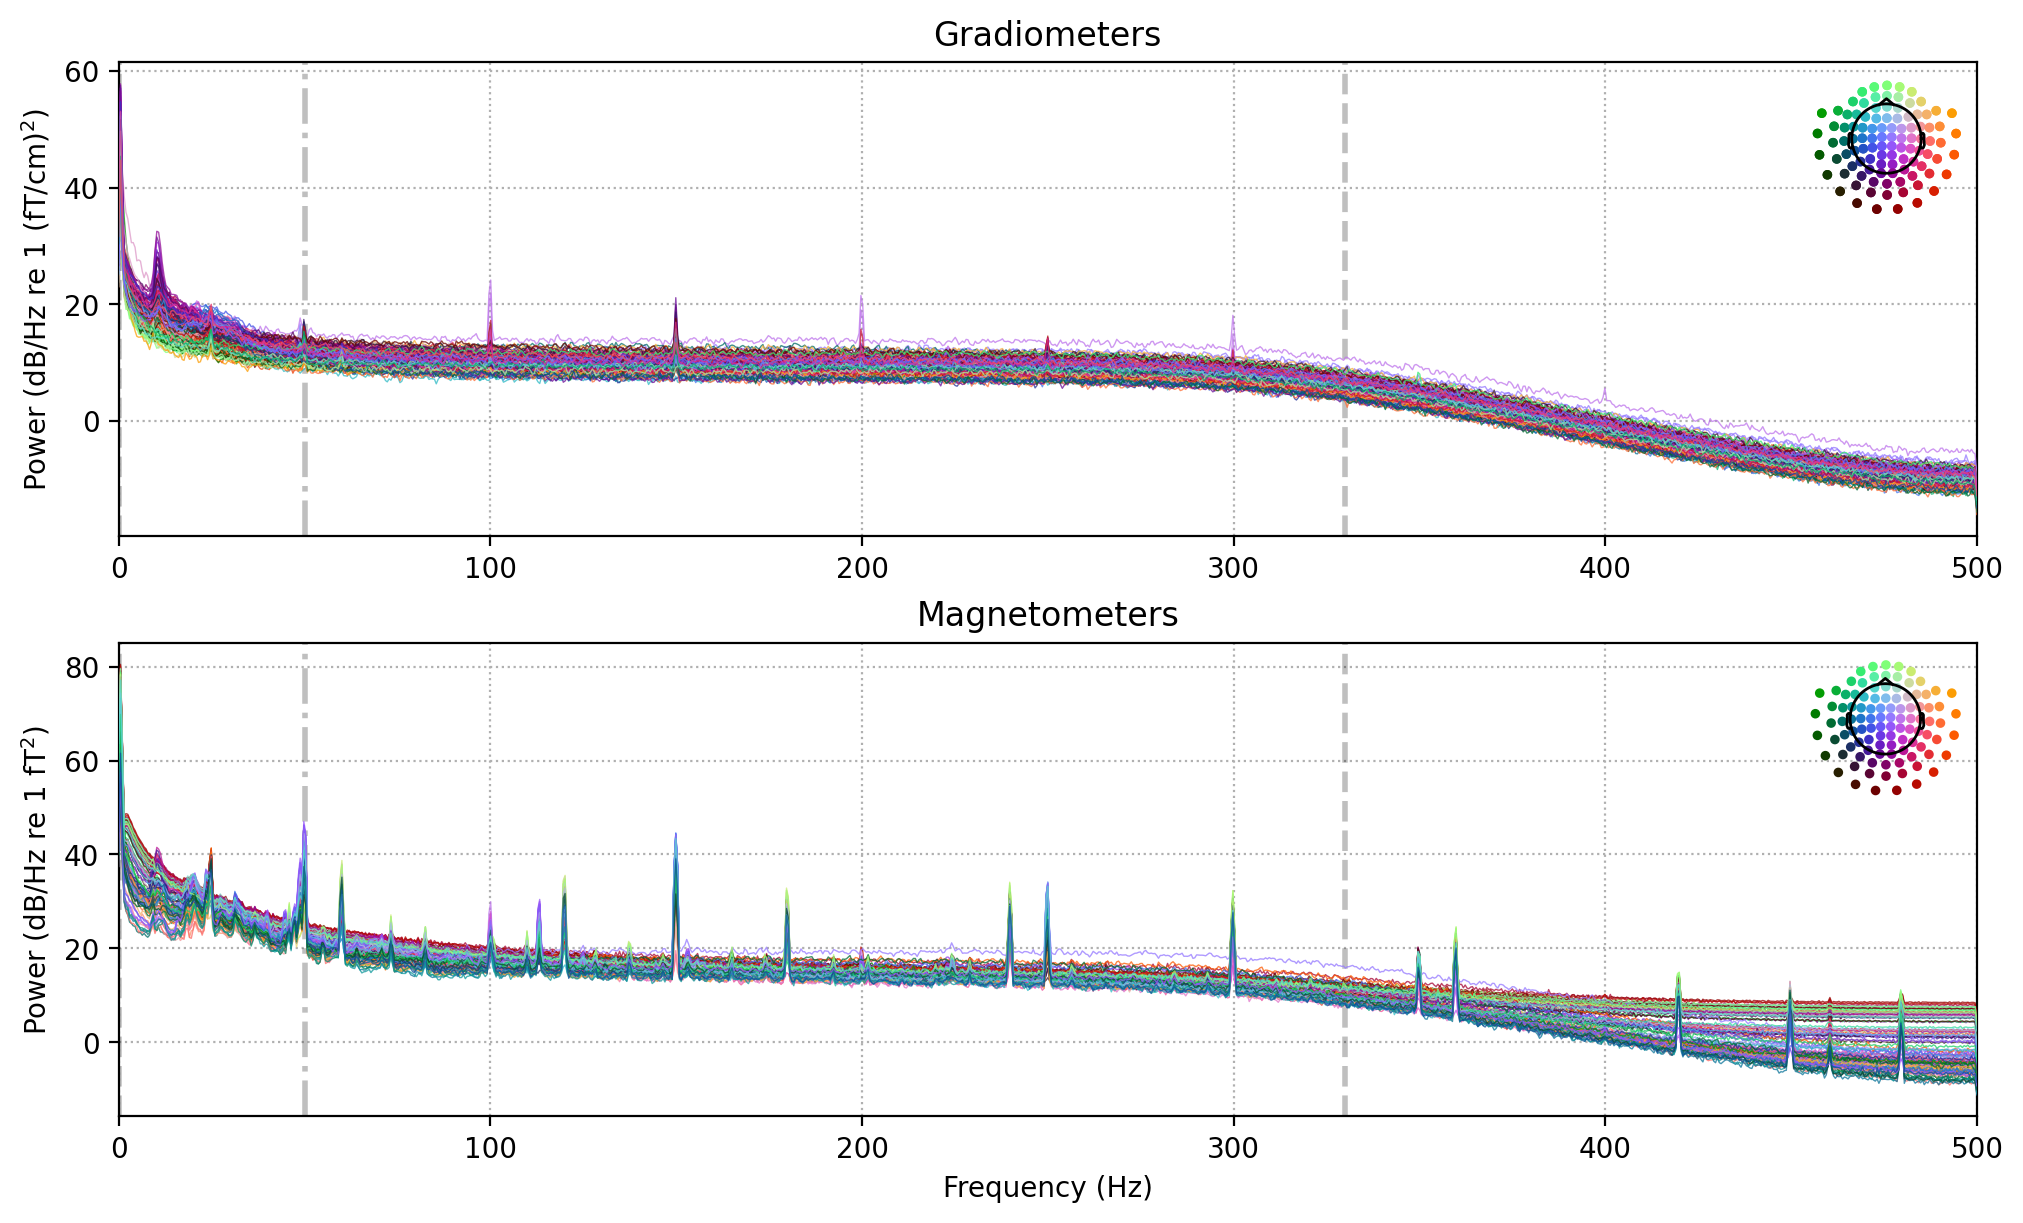

In [7]:
raw.compute_psd().plot()

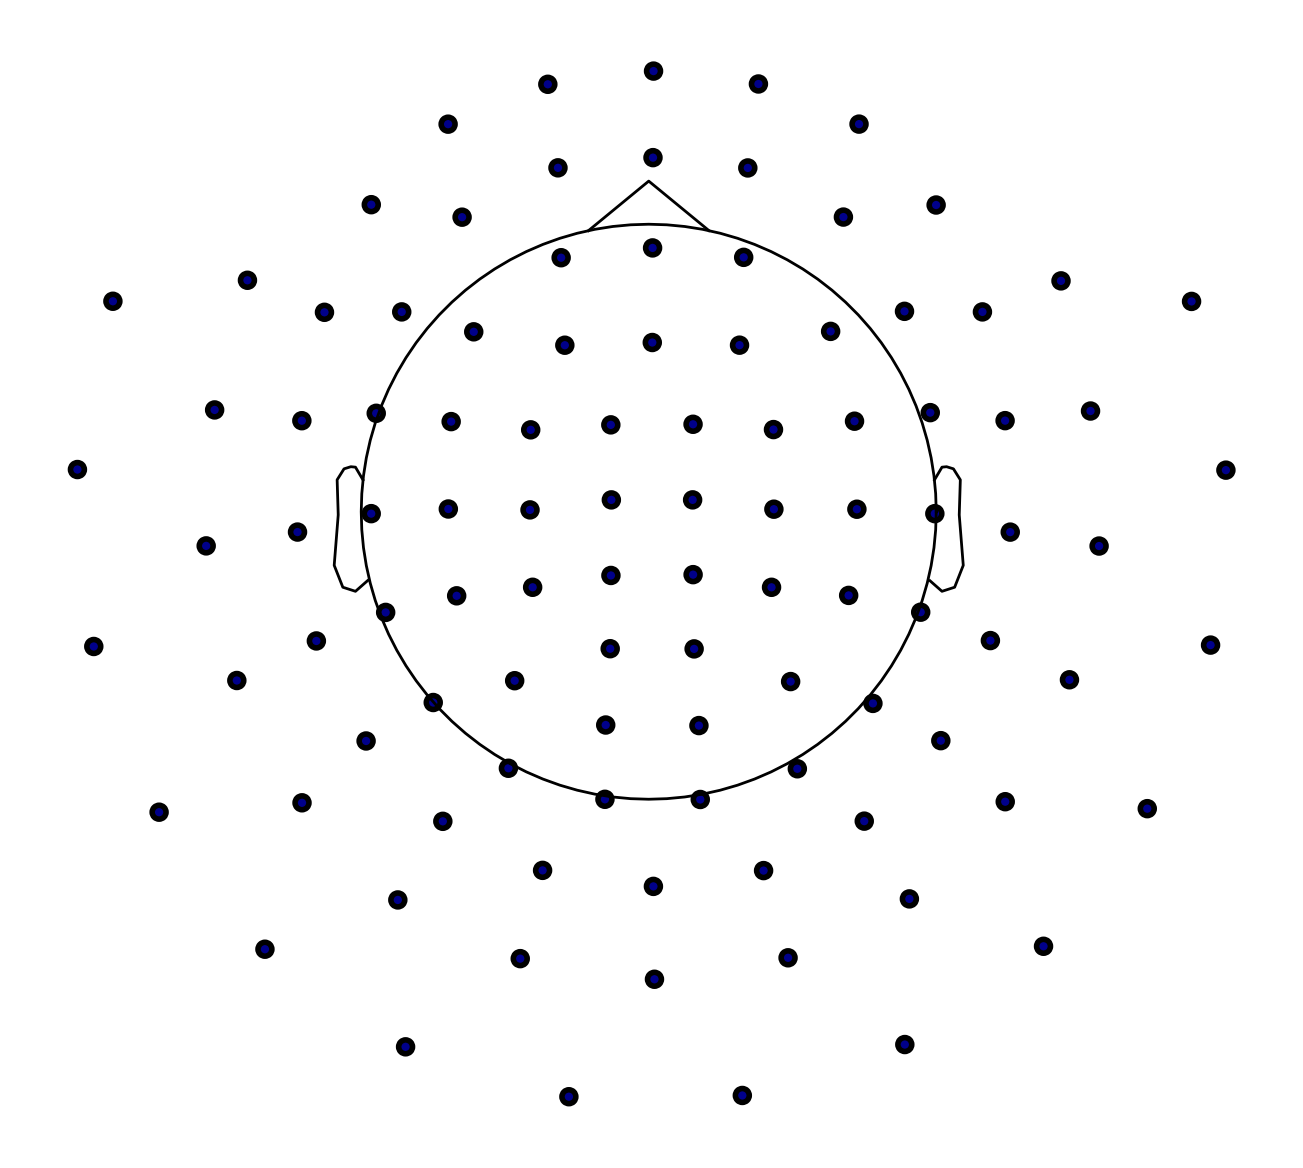

In [8]:
raw.plot_sensors(ch_type="mag")

## detecting artefacts

In [9]:
ssp_projectors = raw.info["projs"]
raw.del_proj()

<Raw | run01.fif, 328 x 384000 (384.0 s), ~966.0 MiB, data loaded>

In [10]:
fig = raw.compute_psd(tmax=np.inf, fmax=250).plot(
    average=True, amplitude=False, picks="data", exclude="bads"
)
# add some arrows at 60 Hz and its harmonics:
for ax in fig.axes[1:]:
    freqs = ax.lines[-1].get_xdata()
    psds = ax.lines[-1].get_ydata()
    for freq in (60, 120, 180, 240):
        idx = np.searchsorted(freqs, freq)
        ax.arrow(
            x=freqs[idx],
            y=psds[idx] + 18,
            dx=0,
            dy=-12,
            color="red",
            width=0.1,
            head_width=3,
            length_includes_head=True,
        )   

Effective window size : 2.048 (s)
Plotting power spectral density (dB=True).


In [11]:
ecg_epochs = mne.preprocessing.create_ecg_epochs(raw)
ecg_epochs.plot_image(combine="mean")

Reconstructing ECG signal from Magnetometers
Setting up band-pass filter from 8 - 16 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 8.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 7.75 Hz)
- Upper passband edge: 16.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 16.25 Hz)
- Filter length: 10000 samples (10.000 s)

Number of ECG events detected : 571 (average pulse 89.21875 / min.)
Not setting metadata
571 matching events found
No baseline correction applied
Using data from preloaded Raw for 571 events and 1001 original time points ...
1 bad epochs dropped
Not setting metadata
570 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
570 matching events found
No baseline correction applied
0 projection items activated
combining

[<Figure size 1280x960 with 3 Axes>, <Figure size 1280x960 with 3 Axes>]

In [12]:
avg_ecg_epochs = ecg_epochs.average().apply_baseline((-0.5, -0.2))

Applying baseline correction (mode: mean)


In [13]:
avg_ecg_epochs.plot_joint(times=[-0.25, -0.025, 0, 0.025, 0.25])

No projector specified for this dataset. Please consider the method self.add_proj.


[<Figure size 1600x840 with 8 Axes>, <Figure size 1600x840 with 8 Axes>]

In [14]:
eog_epochs = mne.preprocessing.create_eog_epochs(raw, baseline=(-0.5, -0.2))
eog_epochs.plot_image(combine="mean")
eog_epochs.average().plot_joint()

RuntimeError: No EOG channel(s) found

## triggers

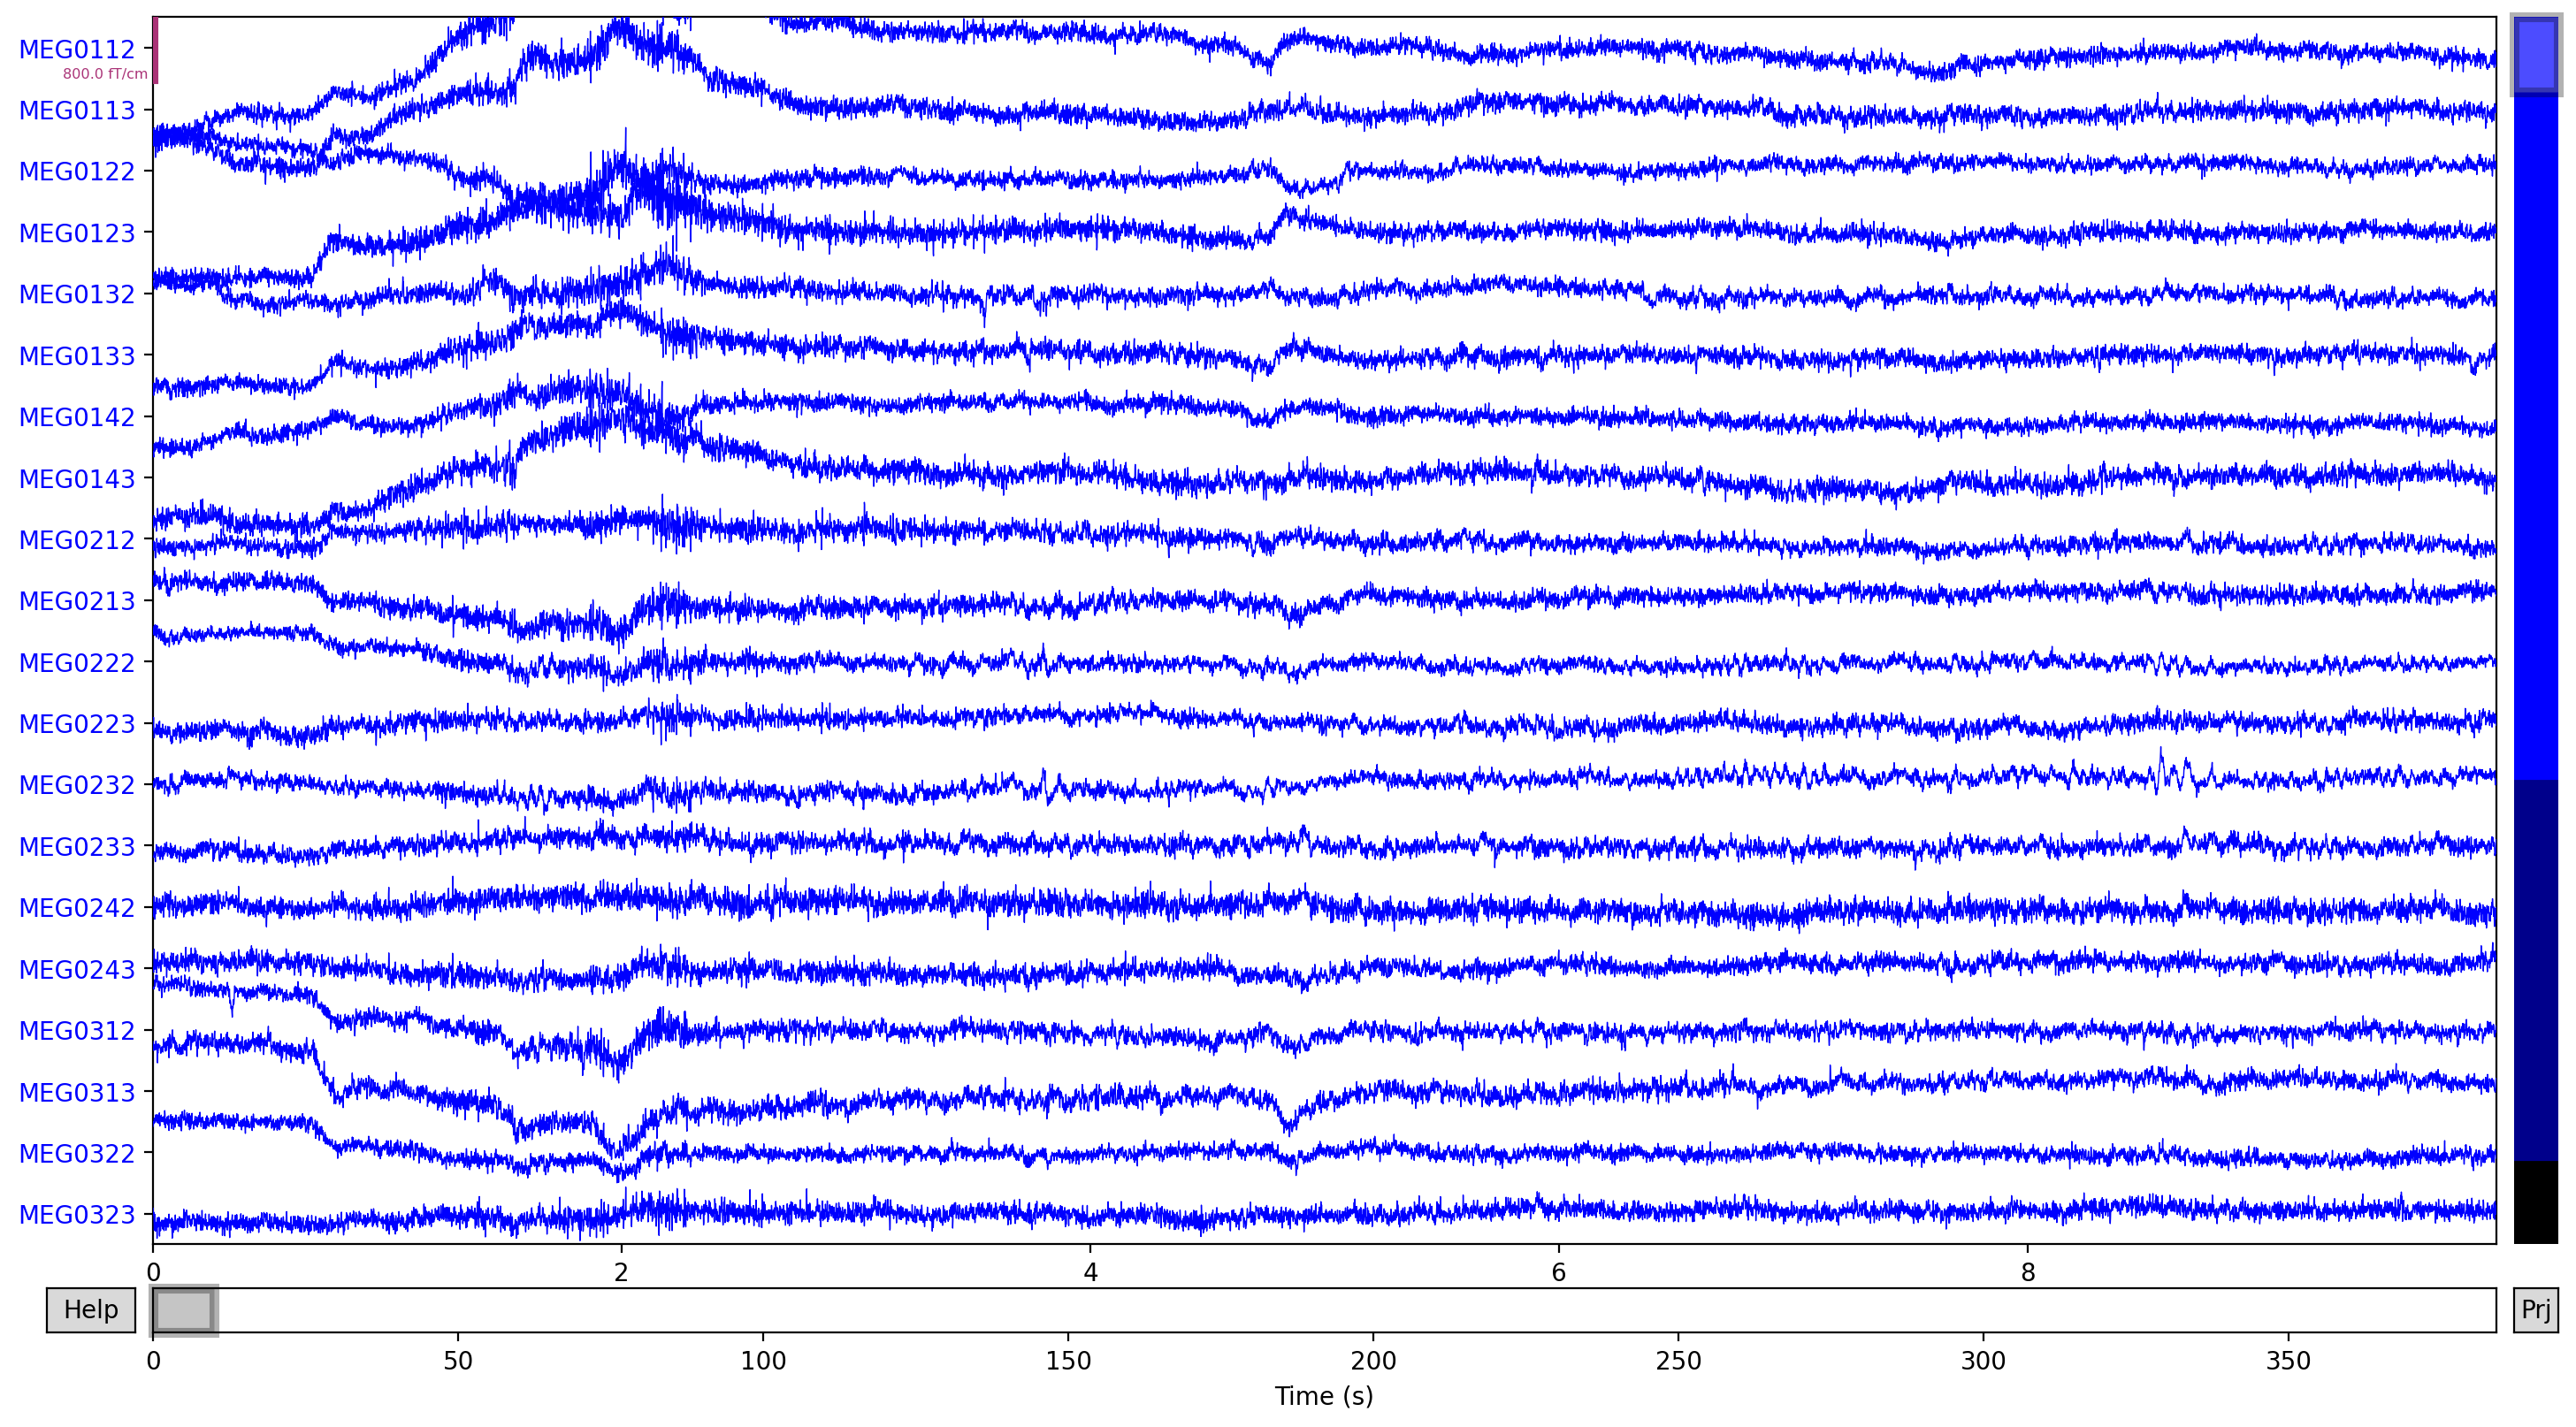

Channels marked as bad:
none
Channels marked as bad:
none


In [ ]:
raw.plot()

In [52]:
events = mne.find_events(raw)
print(events[:5])  # show the first 5

Finding events on: STI101
225 events found on stim channel STI101
Event IDs: [ 96 128 129 130 131 132 133 134 135 144 255]
[[544918      0    255]
 [548011      0    128]
 [548680      0    129]
 [549688      0    144]
 [555960      0     96]]


In [53]:
event_dict = {
    "start of block": 255,
    "start of sequence": 128,
    "stimulus/first": 129,
    "stimulus/second": 130,
    "stimulus/third": 131,
    "stimulus/fourth": 132,
    "stimulus/fifth": 133,
    "stimulus/sixth": 134,
    "stimulus/seventh": 135,
    "response presentation": 144,
    "response": 96,
}

In [17]:
fig = mne.viz.plot_events(events, event_id=event_dict, sfreq=raw.info["sfreq"], first_samp=raw.first_samp)

/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_63514/3398464788.py:1: RuntimeWarning: More events than default colors available. You should pass a list of unique colors.
  fig = mne.viz.plot_events(events, event_id=event_dict, sfreq=raw.info["sfreq"], first_samp=raw.first_samp)


In [54]:
sfreq = raw.info["sfreq"]
print(f"the sampling frequency (='sfreq') is {sfreq:.0f} Hz, meaning, the number of samples per second. Events are stored by number of sample. \nHaving the sampling frequency enables the events' extraction")

the sampling frequency (='sfreq') is 1000 Hz, meaning, the number of samples per second. Events are stored by number of sample. 
Having the sampling frequency enables the events' extraction


In [55]:
events_table = mne.find_events(raw, stim_channel='STI101')
events_table = pd.DataFrame(events_table, columns = ["sample_index", "zero", "event_code"])
events_table["event_times(s)"] = (events_table["sample_index"] - raw.first_samp) / sfreq
events_table["trigger_duration(ms)"] = events_table["event_times(s)"].diff()*1000
events_table

Finding events on: STI101
225 events found on stim channel STI101
Event IDs: [ 96 128 129 130 131 132 133 134 135 144 255]


,sample_index,zero,event_code,event_times(s),trigger_duration(ms)
0,544918,0,255,15.918,NaN
1,548011,0,128,19.011,3093.0
2,548680,0,129,19.680,669.0
3,549688,0,144,20.688,1008.0
4,555960,0,96,26.960,6272.0
...,...,...,...,...,...
220,889498,0,133,360.498,1501.0
221,890999,0,134,361.999,1501.0
222,892517,0,135,363.517,1518.0
223,893535,0,144,364.535,1018.0


In [21]:
events_table.to_csv(f"events_S0_B1.csv")

histograms of trigger distribution

In [26]:
plt.hist(events_table["trigger_duration(ms)"][events_table["event_code"]==144])
plt.show()

In [27]:
plt.hist(events_table["trigger_duration(ms)"][events_table["event_code"]!=255][events_table["event_code"]!=96][events_table["event_code"]!=144][events_table["event_code"]!=128][events_table["event_code"]!=129])
plt.show()

In [28]:
plt.hist(events_table["trigger_duration(ms)"][events_table["event_code"]!=255][events_table["event_code"]!=96][events_table["event_code"]!=144])
plt.show()

In [29]:
for triggercode in events_table["event_code"].unique() : 
    plt.figure()
    x = events_table["trigger_duration(ms)"][1:,][events_table["event_code"]==triggercode]
    plt.hist(x)
    plt.title(f"histogramme des triggers pour trigger {triggercode}")
    plt.xlabel("temps (ms)")
    plt.show()

In [30]:
event_ids = sorted(events_table["event_code"].unique())

# créer un mapping position -> event id
y_pos = np.arange(len(event_ids))
mapping = dict(zip(event_ids, y_pos))

plt.figure(figsize=(12,6))
plt.grid(alpha = 0.4)

for event_id in event_ids:

    subset = events_table[events_table["event_code"] == event_id]

    plt.scatter(
        subset["event_times(s)"],
        [mapping[event_id]] * len(subset),
        label=f"id:{event_id}; N:{len(subset)}"
    )

plt.xlabel("Time (s)")
plt.ylabel("Event id")

# afficher les vrais labels
plt.yticks(y_pos, event_ids)
plt.show()

compter les triggers par bloc du coup

In [ ]:
Counter(events_table["event_code"])

Counter({128: 32,
         129: 32,
         144: 32,
         96: 32,
         130: 24,
         131: 24,
         132: 16,
         133: 16,
         134: 8,
         135: 8,
         255: 1})

## Epochs

In [34]:
raw.set_channel_types({"EOG061": "eog"})

ValueError: This channel name (EOG061) doesn't exist in info.

In [56]:
reject_criteria = dict(
    mag=4000e-15,  # 4000 fT
    grad=4000e-13,  # 4000 fT/cm
    # eog=250e-6,
)  # 250 µV

In [57]:
epochs = mne.Epochs(
    raw,
    events,
    event_id=event_dict,
    tmin=-0.2,
    tmax=0.5,
    reject=reject_criteria,
    preload=True,
)

Not setting metadata
225 matching events found
Setting baseline interval to [-0.2, 0.0] s
Applying baseline correction (mode: mean)
Created an SSP operator (subspace dimension = 13)
13 projection items activated
Using data from preloaded Raw for 225 events and 701 original time points ...
    Rejecting  epoch based on MAG : ['MEG0141']
    Rejecting  epoch based on GRAD : ['MEG1122']
2 bad epochs dropped


In [58]:
epochs.plot_image(picks=["MEG1332"])

Not setting metadata
223 matching events found
No baseline correction applied
0 projection items activated


[<Figure size 1280x960 with 4 Axes>]

In [62]:
frequencies = np.arange(7, 30, 3)
power = epochs["stimulus/first"].compute_tfr(
    "morlet", n_cycles=2, return_itc=False, freqs=frequencies, decim=3, average=True
)
power.plot(["MEG0532"])

No baseline correction applied


[<Figure size 1280x960 with 2 Axes>]

In [68]:
first_evoked = epochs["stimulus/first"].average()
sec_evoked = epochs["stimulus/second"].average()
third_evoked = epochs["stimulus/third"].average()
fourth_evoked = epochs["stimulus/fourth"].average()
fifth_evoked = epochs["stimulus/fifth"].average()
sixth_evoked = epochs["stimulus/sixth"].average()
seventh_evoked = epochs["stimulus/seventh"].average()



mne.viz.plot_compare_evokeds(
    dict(first=first_evoked, second = sec_evoked, third = third_evoked, fourth=fourth_evoked, fifth = fifth_evoked, sixth = sixth_evoked, seventh = seventh_evoked),
    legend="upper left",
    show_sensors="upper right",
)

Multiple channel types selected, returning one figure per type.
combining channels using RMS (mag channels)
combining channels using RMS (mag channels)
combining channels using RMS (mag channels)
combining channels using RMS (mag channels)
combining channels using RMS (mag channels)
combining channels using RMS (mag channels)
combining channels using RMS (mag channels)
combining channels using RMS (grad channels)
combining channels using RMS (grad channels)
combining channels using RMS (grad channels)
combining channels using RMS (grad channels)
combining channels using RMS (grad channels)
combining channels using RMS (grad channels)
combining channels using RMS (grad channels)


[<Figure size 1600x1200 with 2 Axes>, <Figure size 1600x1200 with 2 Axes>]

Projections have already been applied. Setting proj attribute to True.


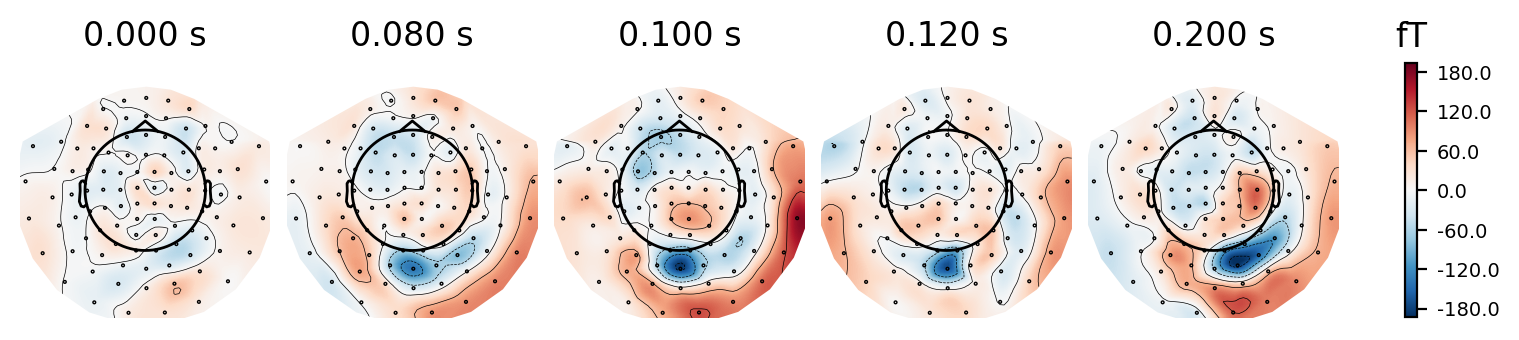

In [74]:
first_evoked.plot_joint(picks="mag")
first_evoked.plot_topomap(times=[0.0, 0.08, 0.1, 0.12, 0.2], ch_type="mag")

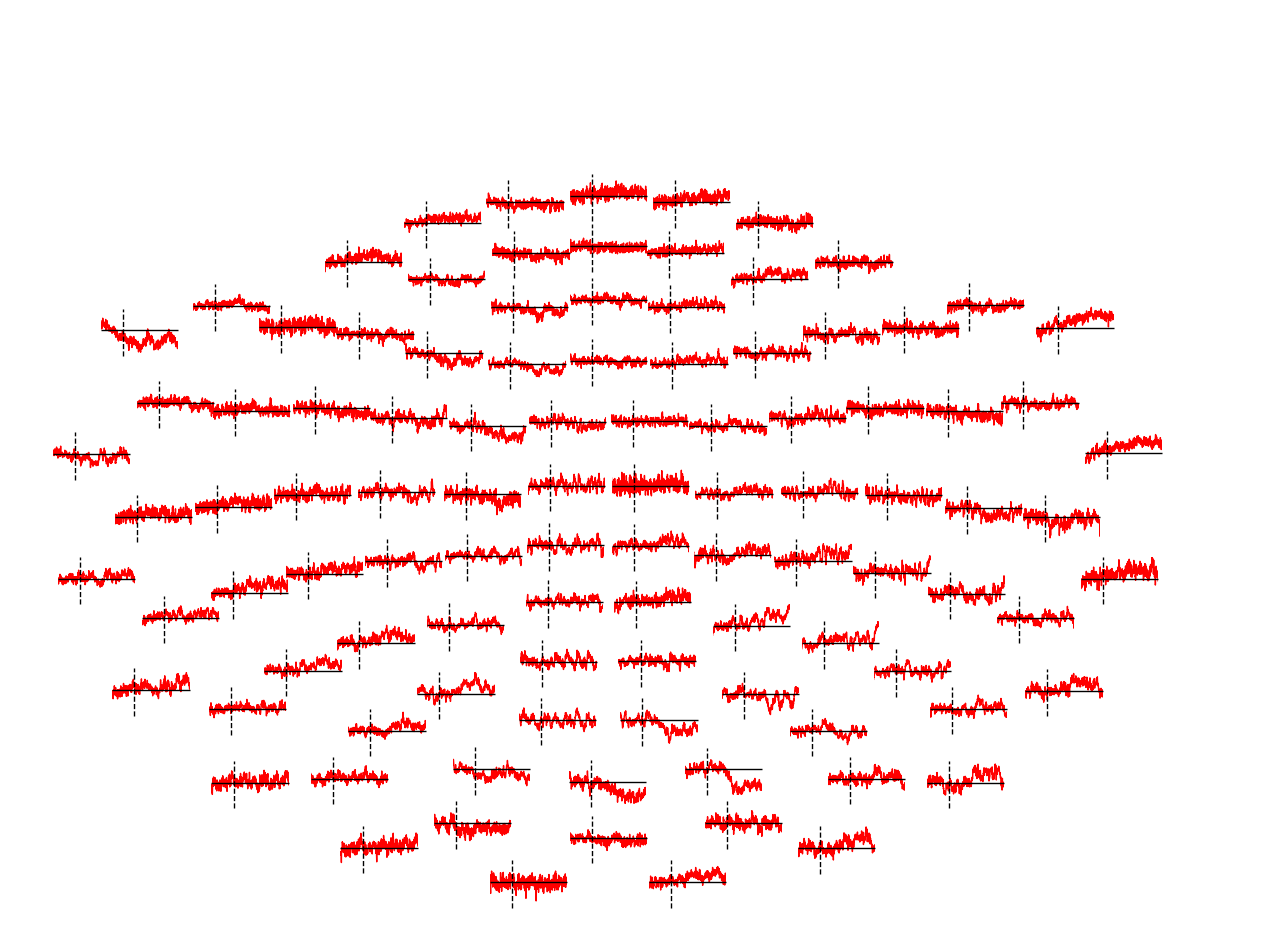

: 

In [ ]:
evoked_diff = mne.combine_evoked([first_evoked, sec_evoked], weights=[1, -1])
evoked_diff.pick(picks="mag").plot_topo(color="r", legend=False)